In [ ]:
import numpy as np
#농어의 길이와 무게
perch_length = np.array([8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 21.0,
       21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 22.5, 22.7,
       23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 27.3, 27.5, 27.5,
       27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 36.5, 36.0, 37.0, 37.0,
       39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 40.0, 42.0, 43.0, 43.0, 43.5,
       44.0])
perch_weight = np.array([5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 110.0,
       115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 130.0,
       150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 197.0,
       218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 514.0,
       556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 820.0,
       850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 1000.0,
       1000.0])

In [ ]:
#학습데이터와 테스트데이터 생성
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(perch_length, perch_weight, random_state=42)
print(train_input.shape, test_input.shape)
train_input = train_input.reshape(-1,1)
test_input = test_input.reshape(-1,1)
print(train_input.shape, test_input.shape)

(42,) (14,)
(42, 1) (14, 1)


In [ ]:
#선형회귀모델 생성
#y = ax + b (x:입력, y:결과, a(coef_),b(intercept_)를 구하는 모델)
from sklearn.linear_model import LinearRegression
import numpy as np

lr = LinearRegression()
lr.fit(train_input, train_target)
print(lr.score(train_input, train_target))
print(lr.score(test_input, test_target))

print(lr.coef_, lr.intercept_)

0.939846333997604
0.8247503123313558
[39.01714496] -709.0186449535477


In [ ]:
#샘플에 대한 예측결과
sample = np.array([[50]])
pred = lr.predict(sample)
print(pred, lr.coef_*sample + lr.intercept_)

[1241.83860323] [[1241.83860323]]


In [ ]:
#테스트 데이터에 대한 예측결과
test_predict = lr.predict(test_input)
pred_target = np.column_stack((test_predict, test_target))
print(pred_target)

[[-381.27462726    5.9       ]
 [  -6.71003561  100.        ]
 [ 363.95284155  250.        ]
 [ 122.04654277  130.        ]
 [ 168.86711673  130.        ]
 [ 851.66715359  820.        ]
 [ 461.49570396  320.        ]
 [ 250.80312115  188.        ]
 [ 812.65000863  900.        ]
 [ 110.34139928  125.        ]
 [ 988.22716096 1000.        ]
 [ -76.94089654   51.5       ]
 [ 383.46141403  250.        ]
 [ 356.14941255  300.        ]]


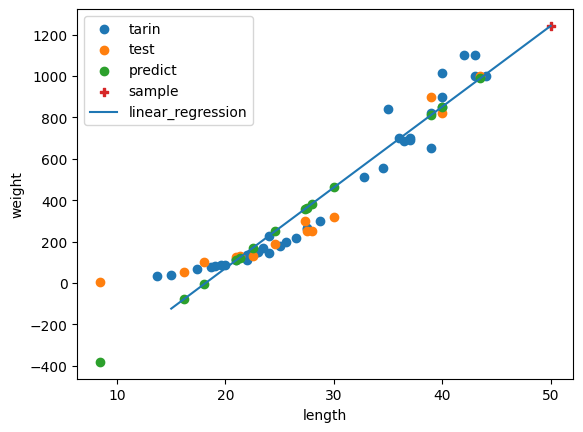

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(train_input, train_target, label='tarin')
plt.scatter(test_input, test_target, label='test')
plt.scatter(test_input, test_predict, label = 'predict')
plt.scatter(sample,pred,marker='P', label='sample')
plt.plot([15,50],[lr.coef_[0]*15+lr.intercept_,lr.coef_[0]*50+lr.intercept_],label='linear_regression')
plt.legend()
plt.xlabel('length')
plt.ylabel('weight')
plt.show()

In [ ]:
#다항회귀
#항을 2개로 증가: 길이의 제곱항, 길이
train_poly = np.column_stack((train_input **2, train_input))
test_poly = np.column_stack((test_input**2, test_input))
#모델 재훈련
lr.fit(train_poly, train_target)
print(lr.score(train_poly, train_target))
print(lr.score(test_poly, test_target))
print(lr.coef_, lr.intercept_) #다항회귀 결과 나온 coef_와 intercept_
#샘플 예측결과
sample = np.array([[5]])
sample_poly =
pred =
print(pred)
#테스트 예측결과
test_pred = lr.predict(test_poly)
print(test_pred)

0.9706807451768623
0.9775935108325122
[  1.01433211 -21.55792498] 116.0502107827827
[33.61888862]
[   6.5349146    56.6511646   290.29593158  117.05874344  144.50252913
  876.66458663  382.21135986  199.55847561  818.09027497  110.65424646
 1097.65040817   33.01314491  307.66468513  283.49043666]


In [ ]:
#재학습 모델 그래프